In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

df = pd.read_csv("../data/charging_clean.csv", parse_dates=["StartDatetime", "EndDatetime"])
df = df.sort_values("StartDatetime").reset_index(drop=True)

df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.day_of_week
df["Month"] = df["StartDatetime"].dt.month
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)
df["TimeOfDay"] = pd.cut(df["Hour"], bins=[-1, 5, 11, 16, 21, 23],
                         labels=["Night", "Morning", "Afternoon", "Evening", "LateEvening"])

guest = df["UserID"] == 0
df["IsGuest"] = guest.astype(int)
df["UserPrevSessions"] = df.groupby("UserID").cumcount()
df.loc[guest, "UserPrevSessions"] = 0
df["UserPrevAvgDemand"] = df.groupby("UserID")["Demand"].transform(
    lambda s: s.shift().expanding().mean())
df.loc[guest, "UserPrevAvgDemand"] = np.nan
df["ChargerPrevSessions"] = df.groupby("ChargerID").cumcount()
df["HasHistory"] = df["UserPrevAvgDemand"].notna().astype(int)
df.to_csv("../data/charging_features.csv", index=False)
print(df.shape)

(72108, 24)


In [10]:
features = ["ChargerCompany", "ChargerType", "Location", "Hour", "DayOfWeek",
            "IsWeekend", "TimeOfDay", "UserPrevSessions", "UserPrevAvgDemand",
            "HasHistory", "IsGuest", "ChargerPrevSessions"]
X = pd.get_dummies(df[features], columns=["Location", "TimeOfDay"], drop_first=True)

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
fill_value = X_train["UserPrevAvgDemand"].mean()
X_train["UserPrevAvgDemand"] = X_train["UserPrevAvgDemand"].fillna(fill_value)
X_test["UserPrevAvgDemand"] = X_test["UserPrevAvgDemand"].fillna(fill_value)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (57686, 27) Test: (14422, 27)


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

y_reg = df["Demand"]
y_train_r, y_test_r = y_reg.iloc[:split], y_reg.iloc[split:]


def eval_reg(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}


reg_results = [eval_reg("Baseline (mean)", y_test_r, np.full(len(y_test_r), y_train_r.mean()))]
reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1),
}
for name, m in reg_models.items():
    m.fit(X_train, y_train_r)
    reg_results.append(eval_reg(name, y_test_r, m.predict(X_test)))

joblib.dump(reg_models["XGBoost"], "../models/xgb_regressor.pkl")
joblib.dump(list(X_train.columns), "../models/regression_columns.pkl")

pd.DataFrame(reg_results).round(3).sort_values("RMSE")

,Model,MAE,MSE,RMSE,R2
5,XGBoost,8.352,129.776,11.392,0.327
6,LightGBM,8.364,130.128,11.407,0.325
4,Gradient Boosting,8.511,132.277,11.501,0.314
3,Random Forest,8.495,134.857,11.613,0.300
2,Decision Tree,8.530,135.329,11.633,0.298
1,Linear Regression,8.720,137.944,11.745,0.284
0,Baseline (mean),10.846,192.904,13.889,-0.001


UserPrevAvgDemand              0.2823
Hour                           0.0764
Location_camping               0.0606
ChargerType                    0.0582
Location_hotel                 0.0469
Location_apartment             0.0466
Location_market                0.0446
TimeOfDay_Afternoon            0.0436
TimeOfDay_Morning              0.0323
IsGuest                        0.0313
Location_public parking lot    0.0297
Location_company               0.0285
UserPrevSessions               0.0268
Location_restaurant            0.0239
Location_public area           0.0224
dtype: float32


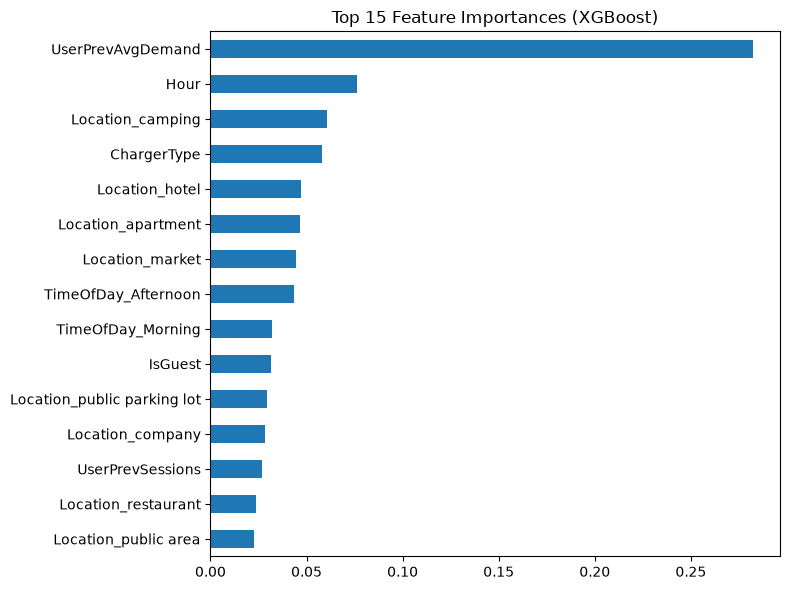

In [12]:
imp = pd.Series(reg_models["XGBoost"].feature_importances_, index=X_train.columns)
top = imp.sort_values(ascending=False).head(15)
print(top.round(4))

top.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 Feature Importances (XGBoost)")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

threshold = df["Demand"].iloc[:split].median()
y_clf = (df["Demand"] >= threshold).astype(int)
y_train_c, y_test_c = y_clf.iloc[:split], y_clf.iloc[split:]
print("Threshold:", threshold, "| Train High share:", y_train_c.mean().round(3))


def eval_clf(name, y_true, y_pred, y_prob):
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob)}


scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

clf_results = []
for name, m in {"Logistic Regression": LogisticRegression(max_iter=1000),
                "KNN": KNeighborsClassifier(n_neighbors=25, n_jobs=-1)}.items():
    m.fit(Xs_train, y_train_c)
    clf_results.append(eval_clf(name, y_test_c, m.predict(Xs_test), m.predict_proba(Xs_test)[:, 1]))

tree_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1),
}
for name, m in tree_models.items():
    m.fit(X_train, y_train_c)
    clf_results.append(eval_clf(name, y_test_c, m.predict(X_test), m.predict_proba(X_test)[:, 1]))

joblib.dump(tree_models["Random Forest"], "../models/rf_classifier.pkl")
joblib.dump(list(X_train.columns), "../models/classification_columns.pkl")
joblib.dump(threshold, "../models/demand_threshold.pkl")

pd.DataFrame(clf_results).round(3).sort_values("ROC-AUC", ascending=False)

Threshold: 14.36 | Train High share: 0.5


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,XGBoost,0.714,0.680,0.783,0.728,0.792
5,LightGBM,0.716,0.683,0.778,0.727,0.791
3,Random Forest,0.712,0.681,0.770,0.722,0.790
2,Decision Tree,0.702,0.663,0.791,0.721,0.779
0,Logistic Regression,0.695,0.683,0.699,0.691,0.773
1,KNN,0.698,0.675,0.732,0.702,0.771


In [14]:
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

rng = np.random.RandomState(42)
high_idx = y_train_c[y_train_c == 1].index
normal_idx = y_train_c[y_train_c == 0].index
keep_high = rng.choice(high_idx, size=int(len(high_idx) * 0.2), replace=False)
imb_idx = normal_idx.union(pd.Index(keep_high))
X_imb, y_imb = X_train.loc[imb_idx], y_train_c.loc[imb_idx]

samplers = {"No resampling": None, "Random Oversampling": RandomOverSampler(random_state=42),
            "SMOTE": SMOTE(random_state=42), "ADASYN": ADASYN(random_state=42)}
rows = []
for name, s in samplers.items():
    Xr_, yr_ = (X_imb, y_imb) if s is None else s.fit_resample(X_imb, y_imb)
    m = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42).fit(Xr_, yr_)
    rows.append(eval_clf(name, y_test_c, m.predict(X_test), m.predict_proba(X_test)[:, 1]))
pd.DataFrame(rows).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,No resampling,0.583,0.866,0.170,0.284,0.783
1,Random Oversampling,0.690,0.713,0.611,0.658,0.776
2,SMOTE,0.658,0.752,0.445,0.559,0.778
3,ADASYN,0.653,0.745,0.436,0.550,0.775


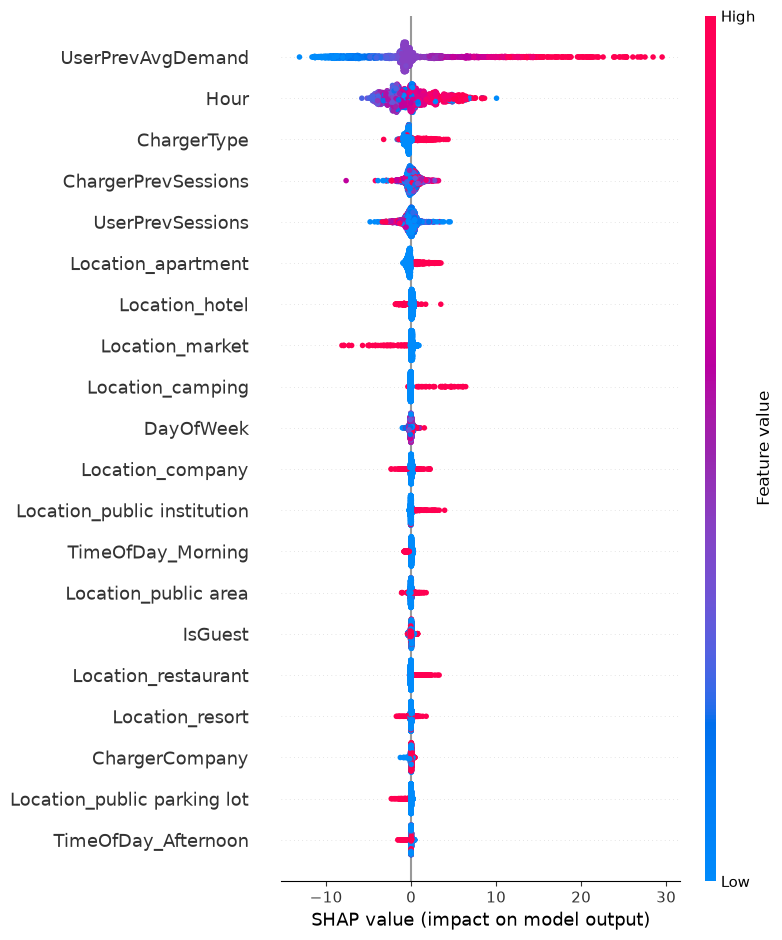

In [15]:
import shap

X_sample = X_test.sample(2000, random_state=42)
explainer = shap.TreeExplainer(reg_models["XGBoost"])
shap_values = explainer(X_sample)

shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.show()

[('Hour > 19.00', 0.09884178903480077), ('15.16 < UserPrevAvgDemand <= 17.92', 0.09784044845236456), ('ChargerType=0', -0.0937601029973171), ('Location_market=0', 0.0830378947911033), ('TimeOfDay_Afternoon=0', 0.06550738020290575), ('TimeOfDay_LateEvening=1', 0.058270026420292664), ('TimeOfDay_Morning=0', 0.050758655936181736), ('Location_hotel=1', -0.04760166956446111), ('HasHistory=0', -0.03925960473688552), ('Location_apartment=0', -0.036639471946997494)]


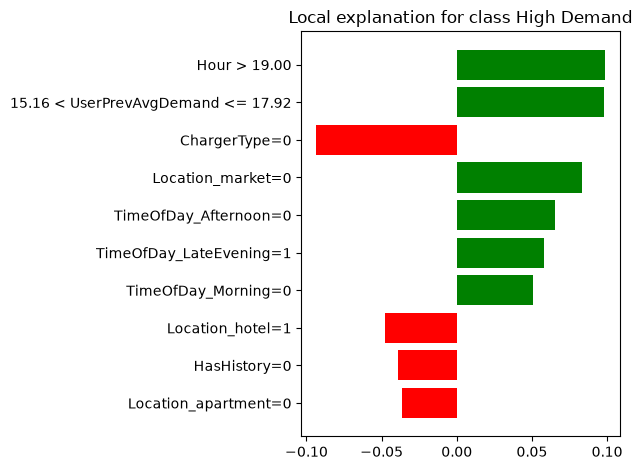

Actual demand: 24.1 | Threshold: 14.36


In [16]:
from lime.lime_tabular import LimeTabularExplainer

clf = tree_models["Random Forest"]
binary_cols = [i for i, c in enumerate(X_train.columns) if set(X_train[c].unique()) <= {0, 1}]

lime_explainer = LimeTabularExplainer(
    X_train.values.astype(float),
    feature_names=list(X_train.columns),
    class_names=["Normal Demand", "High Demand"],
    categorical_features=binary_cols,
    mode="classification",
)
i = 10
exp = lime_explainer.explain_instance(
    X_test.iloc[i].values.astype(float),
    lambda a: clf.predict_proba(pd.DataFrame(a, columns=X_train.columns)),
    num_features=10,
)
print(exp.as_list())
exp.as_pyplot_figure()
plt.tight_layout()
plt.show()
print("Actual demand:", df.loc[X_test.index[i], "Demand"], "| Threshold:", threshold)